# 商品与品类

回答：流量集中在多少个品类/商品上？哪些商品「逛的人多但买的人少」？

数据没有价格字段，所以这一节只谈**流量与转化的结构**，不涉及销售额。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

## 1. 读取数据

In [2]:
data = pd.read_csv(
    'data/UserBehavior_clean.csv',
    usecols=['item_id', 'category_id', 'behavior_type'],
    dtype={'item_id': 'int32', 'category_id': 'int32', 'behavior_type': 'category'},
    encoding='utf-8-sig',
)
data['is_pv'] = (data['behavior_type'] == 'pv').astype('int8')
data['is_cf'] = data['behavior_type'].isin(['cart', 'fav']).astype('int8')
data['is_buy'] = (data['behavior_type'] == 'buy').astype('int8')
data = data.drop(columns=['behavior_type'])
print(data.shape)

print('商品数:', data['item_id'].nunique())
print('品类数:', data['category_id'].nunique())

(100095231, 5)


商品数: 4161138


品类数: 9437


## 2. 品类结构：TOP10 与集中度

In [3]:
cat = data.groupby('category_id')[['is_pv', 'is_cf', 'is_buy']].sum()
cat.columns = ['浏览量', '加购收藏量', '购买量']
cat['购买率(%)'] = (cat['购买量'] / cat['浏览量'] * 100).round(2)

top_cat = cat.nlargest(10, '浏览量')
top_cat['流量占比(%)'] = (top_cat['浏览量'] / cat['浏览量'].sum() * 100).round(2)
top_cat

,浏览量,加购收藏量,购买量,购买率(%),流量占比(%)
category_id,,,,,
4756105,4477682,354519,28258,0.63,4.99
2355072,3151734,209108,12423,0.39,3.52
4145813,3150716,285085,31658,1.00,3.51
3607361,2976359,180436,12721,0.43,3.32
982926,2798730,243043,24825,0.89,3.12
2520377,2029469,153545,9812,0.48,2.26
4801426,1864651,190464,26495,1.42,2.08
1320293,1793240,148916,17137,0.96,2.00
2465336,1504738,139222,13350,0.89,1.68


In [4]:
# 帕累托：品类按浏览量从高到低排序，看多少个品类吃掉 80% 流量
cat_sorted = cat['浏览量'].sort_values(ascending=False)
cum_share = cat_sorted.cumsum() / cat_sorted.sum()
n80 = int((cum_share <= 0.8).sum()) + 1

print(f'总品类数 {len(cat_sorted):,}，其中前 {n80} 个品类贡献了约 80% 的浏览')
print(f'前 10 个品类贡献 {cum_share.iloc[9] * 100:.1f}% 的浏览')
print(f'前 100 个品类贡献 {cum_share.iloc[99] * 100:.1f}% 的浏览')
print(f'前 {n80} 个品类数占比 {n80 / len(cat_sorted) * 100:.2f}%')

总品类数 9,437，其中前 375 个品类贡献了约 80% 的浏览
前 10 个品类贡献 28.1% 的浏览
前 100 个品类贡献 62.7% 的浏览
前 375 个品类数占比 3.97%


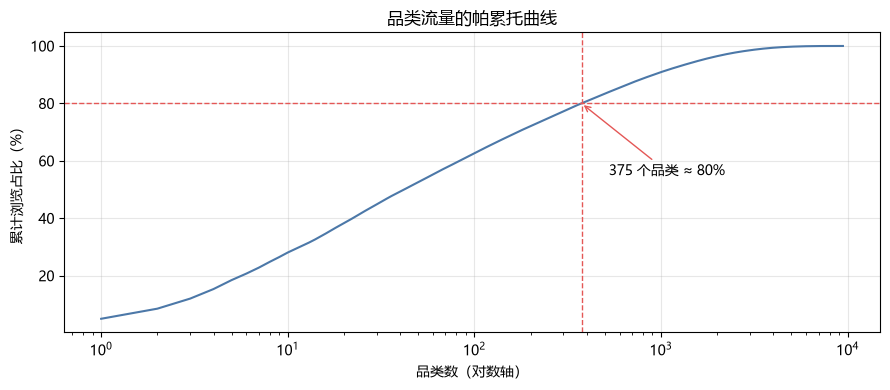

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(1, len(cum_share) + 1)
ax.plot(x, cum_share.values * 100, color='#4C78A8')
ax.axhline(80, color='#E45756', linestyle='--', linewidth=1)
ax.axvline(n80, color='#E45756', linestyle='--', linewidth=1)
ax.annotate(f'{n80} 个品类 ≈ 80%', xy=(n80, 80), xytext=(n80 * 1.4, 55),
            arrowprops=dict(arrowstyle='->', color='#E45756'), fontsize=10)
ax.set_xscale('log')
ax.set_xlabel('品类数（对数轴）')
ax.set_ylabel('累计浏览占比（%）')
ax.set_title('品类流量的帕累托曲线')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. 商品结构：长尾有多长？

In [6]:
item = data.groupby('item_id')[['is_pv', 'is_cf', 'is_buy']].sum()
item.columns = ['浏览量', '加购收藏量', '购买量']

item_pv = item['浏览量'].sort_values(ascending=False)
item_cum = item_pv.cumsum() / item_pv.sum()

n_items = len(item_pv)
top1pct = max(1, int(n_items * 0.01))
print(f'商品总数 {n_items:,}')
print(f'浏览量前 1%（{top1pct:,} 个商品）贡献 {item_cum.iloc[top1pct - 1] * 100:.1f}% 的浏览')
print(f'浏览量前 10%（{int(n_items * 0.1):,} 个商品）贡献 {item_cum.iloc[int(n_items * 0.1) - 1] * 100:.1f}% 的浏览')
print(f'从没被购买过的商品: {(item["购买量"] == 0).sum():,} 个（{(item["购买量"] == 0).mean() * 100:.1f}%）')
print(f'浏览量中位数: {item_pv.median():.0f} 次，均值: {item_pv.mean():.1f} 次')

商品总数 4,161,138
浏览量前 1%（41,611 个商品）贡献 36.4% 的浏览
浏览量前 10%（416,113 个商品）贡献 76.5% 的浏览
从没被购买过的商品: 3,522,176 个（84.6%）
浏览量中位数: 3 次，均值: 21.5 次


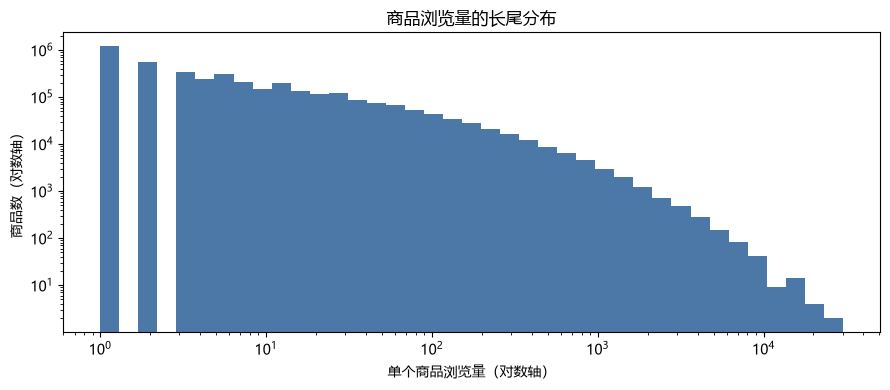

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.logspace(0, np.log10(item_pv.max() + 1), 40)
ax.hist(item_pv, bins=bins, color='#4C78A8')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('单个商品浏览量（对数轴）')
ax.set_ylabel('商品数（对数轴）')
ax.set_title('商品浏览量的长尾分布')
plt.tight_layout()
plt.show()

## 4. 高流量低转化的商品

筛出浏览量 ≥ 5 千、但购买率最低的商品 —— 这些是被大量曝光却没成交的「坑位」，
通常是价格、详情页、或者标题与图片不匹配的问题。

In [8]:
hot = item[item['浏览量'] >= 5000].copy()
hot['购买率(%)'] = (hot['购买量'] / hot['浏览量'] * 100).round(3)
hot['加购收藏率(%)'] = (hot['加购收藏量'] / hot['浏览量'] * 100).round(2)

print(f'浏览量 ≥ 5 千的商品有 {len(hot):,} 个')
hot.nsmallest(10, '购买率(%)')

浏览量 ≥ 5 千的商品有 265 个


,浏览量,加购收藏量,购买量,购买率(%),加购收藏率(%)
item_id,,,,,
1591862,16185,6,0,0.000,0.04
2367945,16190,3,0,0.000,0.02
2683360,6465,191,0,0.000,2.95
2161188,8710,397,1,0.011,4.56
2678768,8139,331,1,0.012,4.07
1550635,5836,117,1,0.017,2.00
2671601,5933,371,1,0.017,6.25
2058655,6256,180,2,0.032,2.88
3371523,17159,64,7,0.041,0.37


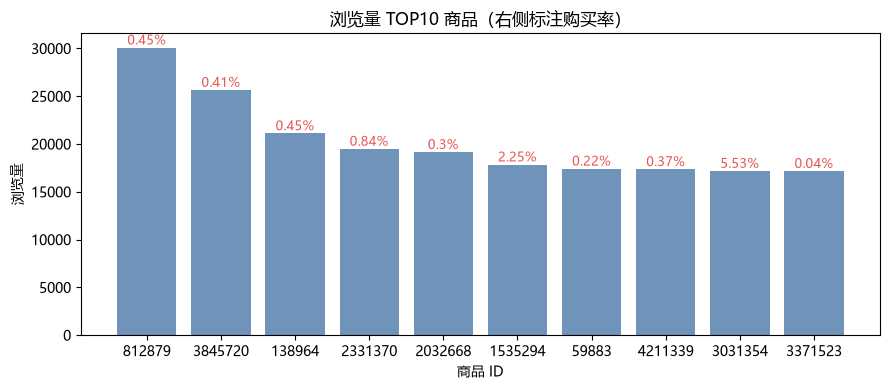

In [9]:
top_view = item.nlargest(10, '浏览量').copy()
top_view['购买率(%)'] = (top_view['购买量'] / top_view['浏览量'] * 100).round(2)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(top_view.index.astype(str), top_view['浏览量'], color='#4C78A8', alpha=0.8, label='浏览量')
ax.set_ylabel('浏览量')
ax.set_xlabel('商品 ID')
ax.set_title('浏览量 TOP10 商品（右侧标注购买率）')

for i, (v, r) in enumerate(zip(top_view['浏览量'], top_view['购买率(%)'])):
    ax.text(i, v, f'{r}%', ha='center', va='bottom', fontsize=9, color='#E45756')

plt.tight_layout()
plt.show()

## 结论

**1. 品类是「集中但不极端」**：4 万多个品类里，前 10 个只占 28.1% 浏览，前 100 个占 62.7%，
375 个品类（占总数的 4%）贡献约 80% 流量。运营上盯住前 300~400 个品类即可覆盖大盘。

**2. 商品是典型的长尾**：416 万个商品中，前 1% 贡献 36.4% 浏览、前 10% 贡献 76.5%；
单个商品浏览中位数只有 3 次，而均值 21.5 次（被头部拉高）。
更关键的是 **84.6% 的商品（352 万个）从未被购买过**，长尾基本是无效库存。

**3. 「高流量低转化」商品要分两类处理**（浏览量 ≥ 5 千的有 265 个）：
- **加购率也极低的**（如 1591862、2367945，1.6 万浏览但加购率不足 0.05%、零成交）：
  更像是曝光不精准或标题/主图与内容不符，问题在**流量入口**
- **有加购但零成交的**（如 2683360，6,465 浏览、191 次加购、0 购买）：
  用户已经有意向却没转化，问题更可能在**价格、库存或运费**

**4. 分析边界**：数据没有价格字段，所以只能算浏览驱动的转化结构，
无法得出 GMV、客单价、价格带贡献这类结论 —— 写报告时不要越界。